# Hourly Pollutant Profiles Normalized to Percent of Max

This notebook reads `data/utah/data_up_to_2025/summed/HW_data_raw_2026-05-23_all.csv`, computes the hourly mean and median for Ozone, VOC, and NOx, and normalizes each pollutant/statistic curve to percent of its own maximum value.

In [1]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "Notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

os.environ.setdefault(
    "MPLCONFIGDIR",
    str(Path(os.environ.get("TMPDIR", "/tmp")) / "improved_isopleths_matplotlib"),
)

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = PROJECT_ROOT / "data/utah/data_up_to_2025/summed/HW_data_raw_2026-05-23_all.csv"
POLLUTANTS = ["Ozone", "VOC", "NOx"]

plt.style.use("seaborn-v0_8-whitegrid")

## Load Data

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["dt"])
df["hour"] = df["dt"].dt.hour

print(f"Loaded {len(df):,} rows from {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Date range: {df['dt'].min()} to {df['dt'].max()}")

df.head()

Loaded 32,402 rows from data/utah/data_up_to_2025/summed/HW_data_raw_2026-05-23_all.csv
Date range: 2021-01-01 00:00:00 to 2025-12-30 23:00:00


,dt,VOC,NOx,Ozone,hour
0,2021-01-01 00:00:00,46.1402,10.90,22.0,0
1,2021-01-01 01:00:00,83.8735,NaN,NaN,1
2,2021-01-01 04:00:00,140.6946,58.50,0.0,4
3,2021-01-01 05:00:00,168.4667,81.20,0.0,5
4,2021-01-01 06:00:00,145.6557,63.05,1.0,6


## Hourly Mean and Median

In [3]:
hourly_stats = (
    df.groupby("hour")[POLLUTANTS]
    .agg(["mean", "median"])
    .reindex(range(24))
)

hourly_stats.round(2)

Ozone           VOC           NOx       
       mean median   mean median   mean median
hour                                          
0     24.83   27.0  60.77  39.77  19.35   9.52
1     24.65   27.0  62.87  40.77  17.19   8.72
2     23.15   24.5  62.16  44.34  17.65   9.00
3     22.83   24.0  61.80  43.57  18.37   9.45
4     21.40   23.0  63.64  46.89  20.24  11.30
5     18.82   19.0  68.55  51.82  25.41  15.95
6     17.34   16.5  78.09  61.81  32.27  22.45
7     19.23   20.0  86.07  63.56  36.68  23.50
8     24.32   26.0  83.36  54.97  34.20  19.15
9     31.02   33.0  62.89  42.81  23.70  14.05
10    36.85   37.0  48.38  33.58  16.68   9.80
11    41.07   40.0  41.94  28.95  13.06   7.20
12    43.92   43.0  37.22  23.69  10.76   5.50
13    45.36   44.0  34.30  21.45   9.33   4.45
14    45.56   45.0  34.18  21.26   8.67   4.25
15    45.15   44.0  34.23  21.27   8.31   4.15
16    43.51   44.0  33.46  22.76   8.71   4.45
17    39.69   42.0  38.63  25.69  11.57   5.30
18    34.94   38.0  50.56  31.21  15.85   7.68
19    30.66   34.0  61.52  41.54  19.05  10.35
20    28.60   32.0  61.21  38.86  19.97   9.57
21    28.03   31.0  59.52  34.97  20.26   9.40
22    27.24   30.0  58.64  35.34  19.92   9.70
23    26.43   29.0  58.64  36.74  19.07   9.60

## Normalize Each Curve to Percent of Maximum

Each pollutant/statistic series is divided by its own maximum hourly value, so the peak of every line is 100%.

In [4]:
normalized_hourly = hourly_stats.copy()

for pollutant in POLLUTANTS:
    for statistic in ["mean", "median"]:
        series = normalized_hourly[(pollutant, statistic)]
        max_value = series.max(skipna=True)
        normalized_hourly[(pollutant, statistic)] = series / max_value * 100

normalized_hourly.round(1)

Ozone           VOC           NOx       
       mean median   mean median   mean median
hour                                          
0      54.5   60.0   70.6   62.6   52.7   40.5
1      54.1   60.0   73.0   64.2   46.9   37.1
2      50.8   54.4   72.2   69.8   48.1   38.3
3      50.1   53.3   71.8   68.6   50.1   40.2
4      47.0   51.1   73.9   73.8   55.2   48.1
5      41.3   42.2   79.6   81.5   69.3   67.9
6      38.1   36.7   90.7   97.2   88.0   95.5
7      42.2   44.4  100.0  100.0  100.0  100.0
8      53.4   57.8   96.9   86.5   93.2   81.5
9      68.1   73.3   73.1   67.4   64.6   59.8
10     80.9   82.2   56.2   52.8   45.5   41.7
11     90.2   88.9   48.7   45.5   35.6   30.6
12     96.4   95.6   43.2   37.3   29.3   23.4
13     99.6   97.8   39.9   33.8   25.4   18.9
14    100.0  100.0   39.7   33.4   23.6   18.1
15     99.1   97.8   39.8   33.5   22.7   17.7
16     95.5   97.8   38.9   35.8   23.7   18.9
17     87.1   93.3   44.9   40.4   31.5   22.6
18     76.7   84.4   58.7   49.1   43.2   32.7
19     67.3   75.6   71.5   65.4   51.9   44.0
20     62.8   71.1   71.1   61.1   54.4   40.7
21     61.5   68.9   69.2   55.0   55.2   40.0
22     59.8   66.7   68.1   55.6   54.3   41.3
23     58.0   64.4   68.1   57.8   52.0   40.9

## Plot Percent of Maximum by Hour

Saved plot to plots/hourly_normalized_pollutant_max.png


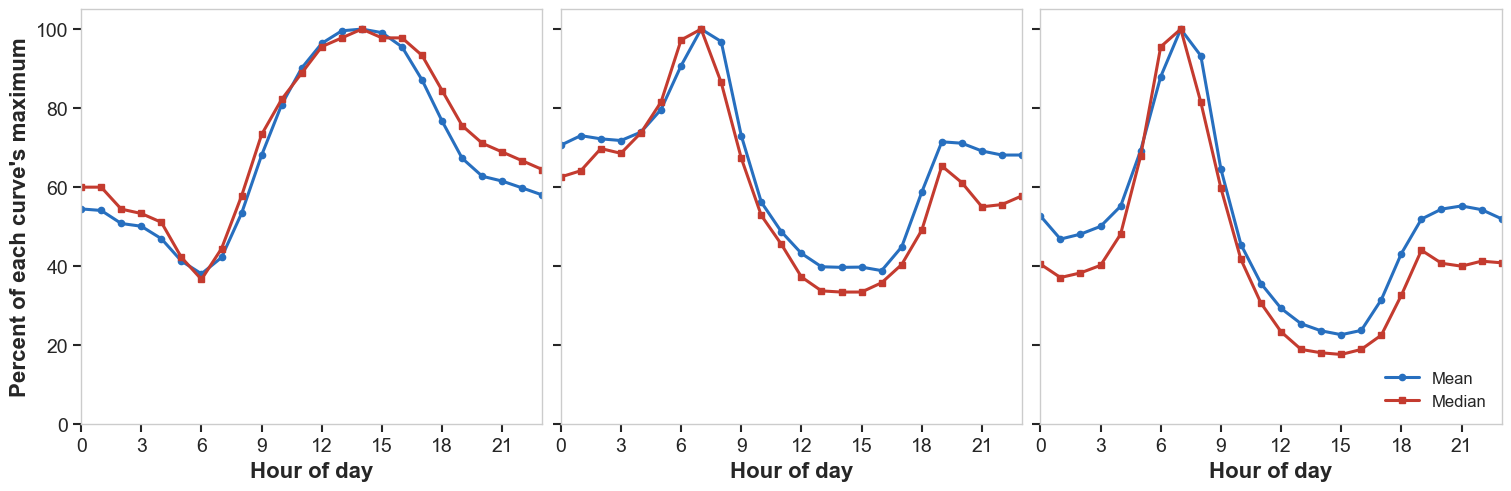

In [5]:
fig, axes = plt.subplots(
    1,
    len(POLLUTANTS),
    figsize=(15, 4.8),
    sharey=True,
    constrained_layout=True,
)

line_styles = {
    "mean": {"color": "#276FBF", "marker": "o", "label": "Mean"},
    "median": {"color": "#C43B2F", "marker": "s", "label": "Median"},
}

for ax, pollutant in zip(axes, POLLUTANTS):
    for statistic, style in line_styles.items():
        ax.plot(
            normalized_hourly.index,
            normalized_hourly[(pollutant, statistic)],
            linewidth=2.2,
            markersize=4.5,
            **style,
        )

    ax.set_xlabel("Hour of day", fontsize=16, fontweight="bold")
    ax.set_xlim(0, 23)
    ax.set_ylim(0, 105)
    ax.set_xticks(range(0, 24, 3))
    ax.grid(False)
    ax.tick_params(axis="both", which="major", labelsize=14, length=6, width=1.5)

axes[0].set_ylabel("Percent of each curve's maximum", fontsize=16, fontweight="bold")
axes[-1].legend(frameon=False, loc="lower right", fontsize=12)

output_path = PROJECT_ROOT / "plots/hourly_normalized_pollutant_max.png"
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Saved plot to {output_path.relative_to(PROJECT_ROOT)}")
plt.show()

Saved plot to plots/hourly_normalized_pollutant_max_single_axis.png


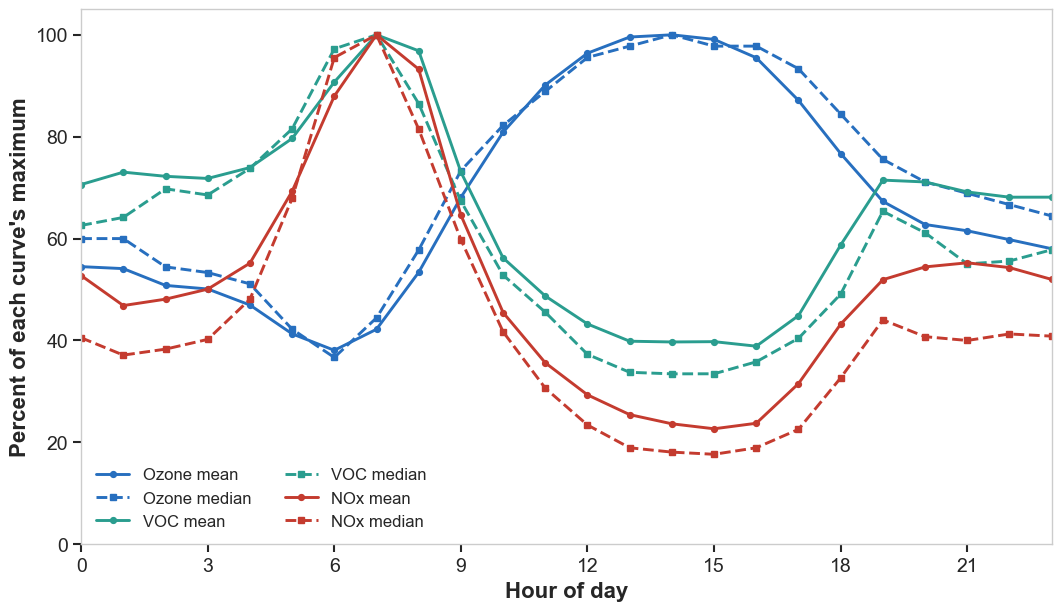

In [ ]:
fig, ax = plt.subplots(figsize=(10.5, 6), constrained_layout=True)

pollutant_colors = {
    "Ozone": "#276FBF",
    "VOC": "#2A9D8F",
    "NOx": "#C43B2F",
}
statistic_styles = {
    "mean": {"linestyle": "-", "marker": "o", "label_suffix": "mean"},
    "median": {"linestyle": "--", "marker": "s", "label_suffix": "median"},
}

for pollutant in POLLUTANTS:
    for statistic, style in statistic_styles.items():
        ax.plot(
            normalized_hourly.index,
            normalized_hourly[(pollutant, statistic)],
            color=pollutant_colors[pollutant],
            linestyle=style["linestyle"],
            marker=style["marker"],
            linewidth=2.1,
            markersize=4.2,
            label=f"{pollutant} {style['label_suffix']}",
        )

ax.set_xlabel("Hour of day", fontsize=16, fontweight="bold")
ax.set_ylabel("Percent of maximum", fontsize=16, fontweight="bold")
ax.set_xlim(0, 23)
ax.set_ylim(0, 105)
ax.set_xticks(range(0, 24, 3))
ax.grid(False)
ax.tick_params(axis="both", which="major", labelsize=14, length=6, width=1.5)
ax.legend(frameon=False, ncol=2, fontsize=12)

output_path = PROJECT_ROOT / "plots/hourly_normalized_pollutant_max_single_axis.png"
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Saved plot to {output_path.relative_to(PROJECT_ROOT)}")
plt.show()